# TF-IDF + logistic regression baseline: risk themes in mental-health app reviews

This notebook does our four tasks, in order:

1. **Convert review text into model-ready features using TF-IDF.**
2. **Compare a few settings** (word 1-2-grams, character n-grams, minimum document frequency) and **pick one using cross-validation.**
3. **Train an interpretable baseline**: one logistic regression per risk theme.
4. **Record macro F1, per-class precision and recall, and the confusion matrix** from cross-validation, and **save the results table.**

In [1]:
!pip install -q iterative-stratification

In [2]:
import os
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold   # keeps every theme represented in every fold
except ImportError:
    MultilabelStratifiedKFold = None

try:
    display            # available in Colab / Jupyter
except NameError:
    display = print

pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 120)

# setting
SEED = 42
N_SPLITS = 5            # CV folds
N_REPEATS = int(os.environ.get('N_REPEATS', 3))   # how many times to repeat the whole CV
INNER_SPLITS = 3        # inner folds used to choose C and the threshold
C_GRID = [0.1, 0.3, 1, 3, 10, 30]   # small C = strong regularisation (simpler model)
MIN_POS_TO_TRAIN = 5    # fewer positives than this: the theme is skipped
MIN_POS_RELIABLE = 15   # fewer than this: we still train, but the scores are very unreliable

DATA_PATH = os.environ.get('DATA_PATH', '/content/drive/MyDrive/dataset/ai_subset_clean_sample_100_labeled_merged.csv')
OUT_DIR = os.environ.get('OUT_DIR', '/content/drive/MyDrive/dataset/results')

In [3]:
# Mount Google Drive
if DATA_PATH.startswith('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
os.makedirs(OUT_DIR, exist_ok=True)

# Every fold has each theme
print('Same folds for every theme (iterative stratification):', MultilabelStratifiedKFold is not None)
print('Results will be saved to:', OUT_DIR)

Mounted at /content/drive
Same folds for every theme (iterative stratification): True
Results will be saved to: /content/drive/MyDrive/dataset/results


## Load the labelled data

Works with either label format: `dependence / attachment / isolation / crisis` with `TRUE/FALSE`, or `label_dependence ...` with `Yes`/blank (blank = the theme is not present). **Other / None** is derived as "no theme present".

A theme gets a model only if it has at least `MIN_POS_TO_TRAIN` positive reviews. Our pilot file has very few `isolation` examples and only one `crisis` example, so expect those to be flagged.

In [4]:
COLUMN_ALIASES = {
    'dependence': ['dependence', 'label_dependence'],
    'attachment': ['attachment', 'label_attachment'],
    'isolation':  ['isolation', 'label_isolation_displacement'],
    'crisis':     ['crisis', 'label_crisis_response_frustration'],
}
THEMES = list(COLUMN_ALIASES)
TRUE_VALUES = {'TRUE', 'YES', '1'}
KNOWN_VALUES = TRUE_VALUES | {'FALSE', 'NO', '0', 'NAN', ''}

raw = pd.read_csv(DATA_PATH)
lab = raw.copy()
for theme, aliases in COLUMN_ALIASES.items():
    col = next((a for a in aliases if a in raw.columns), None)
    assert col is not None, f'no column found for {theme}; looked for {aliases}'
    values = raw[col].fillna('').astype(str).str.strip().str.upper()
    unknown = set(values.unique()) - KNOWN_VALUES
    assert not unknown, f'unexpected values in {col}: {unknown}'
    lab[theme] = values.isin(TRUE_VALUES)

lab = lab.dropna(subset=['review']).reset_index(drop=True)
if 'UID' not in lab.columns:
    lab['UID'] = np.arange(len(lab))

X = lab['review'].astype(str)
texts = X.tolist()
lab['any_theme'] = lab[THEMES].any(axis=1)

n_dup = int(X.str.strip().str.lower().duplicated().sum())
if n_dup:
    print(f'WARNING: {n_dup} duplicate reviews. Duplicates can end up in both train and test folds and inflate scores.')

counts = pd.DataFrame({'n_pos': [int(lab[t].sum()) for t in THEMES]}, index=THEMES)
counts['base_rate'] = counts['n_pos'] / len(lab)
counts['status'] = np.where(counts['n_pos'] < MIN_POS_TO_TRAIN, 'skipped: too few positives',
                   np.where(counts['n_pos'] < MIN_POS_RELIABLE, 'trained, but scores unreliable', 'trained'))
print(f'{len(lab)} reviews; {int((~lab["any_theme"]).sum())} have no theme (Other / None)')
display(counts.round(3))

TRAIN_THEMES = [t for t in THEMES if counts.loc[t, 'n_pos'] >= MIN_POS_TO_TRAIN]
RELIABLE_THEMES = [t for t in THEMES if counts.loc[t, 'n_pos'] >= MIN_POS_RELIABLE]
SELECT_THEMES = RELIABLE_THEMES if RELIABLE_THEMES else TRAIN_THEMES
assert TRAIN_THEMES, 'No theme has enough positive examples to train a model.'

y_all = {t: lab[t].astype(int).to_numpy() for t in TRAIN_THEMES}
y_all['other_none'] = (np.column_stack([y_all[t] for t in TRAIN_THEMES]).sum(axis=1) == 0).astype(int)
CLASSES = TRAIN_THEMES + ['other_none']
if len(TRAIN_THEMES) < len(THEMES):
    skipped = [t for t in THEMES if t not in TRAIN_THEMES]
    print(f'\nNote: {skipped} not modelled, so Other / None here means "none of {TRAIN_THEMES}".')

Y_strat = lab[TRAIN_THEMES].astype(int).to_numpy()


def make_splits(seed):
    """List of (train_idx, test_idx) pairs for one run of 5-fold CV."""
    if MultilabelStratifiedKFold is not None:
        return list(MultilabelStratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed).split(X, Y_strat))
    return list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed).split(X, lab['any_theme'].astype(int)))

100 reviews; 54 have no theme (Other / None)


,n_pos,base_rate,status
dependence,18,0.18,trained
attachment,24,0.24,trained
isolation,5,0.05,"trained, but scores unreliable"
crisis,1,0.01,skipped: too few positives



Note: ['crisis'] not modelled, so Other / None here means "none of ['dependence', 'attachment', 'isolation']".


## TF-IDF features, compare settings, pick one by cross-validation

**TF-IDF** turns each review into numbers: each word (or word pair, or character chunk) gets a weight that is high when the term is frequent in that review but rare across all reviews.

We try five settings:

- **word 1-gram:** single words only.
- **word 1-2-gram:** single words and two-word phrases (so "no one" and "every day" can count).
- **character n-grams:** chunks of 2-5 characters inside words; this helps with typos and slang.
- **`min_df`:** a term must appear in at least this many reviews to be kept. A higher value gives a smaller vocabulary but throws away rare words like "lonely" that may matter.

Each setting is scored with the same simple logistic regression (`C=1`) using the repeated CV. We compare **macro F1** (average F1 across themes at the default 0.5 cut-off) and **AP lift** (average precision divided by the base rate; 1.0 = no better than guessing). We pick the setting with the best **AP lift**, because macro F1 can look decent even when a model has learned nothing. Only themes with at least `MIN_POS_RELIABLE` positives are used to choose, because themes with a handful of examples would just add noise.

In [5]:
CANDIDATES = {
    'word_1gram_mindf2':  dict(analyzer='word', ngram_range=(1, 1), min_df=2, max_df=0.95,
                               sublinear_tf=True, strip_accents='unicode', lowercase=True),
    'word_12gram_mindf2': dict(analyzer='word', ngram_range=(1, 2), min_df=2, max_df=0.95,
                               sublinear_tf=True, strip_accents='unicode', lowercase=True),
    'word_12gram_mindf3': dict(analyzer='word', ngram_range=(1, 2), min_df=3, max_df=0.95,
                               sublinear_tf=True, strip_accents='unicode', lowercase=True),
    'char_35gram_mindf3': dict(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_df=0.95,
                               sublinear_tf=True, lowercase=True),
    'char_25gram_mindf2': dict(analyzer='char_wb', ngram_range=(2, 5), min_df=2, max_df=0.95,
                               sublinear_tf=True, lowercase=True),
}


def make_pipe(vec_kwargs, C=1.0):
    # The TF-IDF step is inside the pipeline / re-fit on each training fold only
    return Pipeline([
        ('tfidf', TfidfVectorizer(**vec_kwargs)),
        ('clf', LogisticRegression(C=C, class_weight='balanced', max_iter=5000)),
    ])


def score_setting(vec_kwargs):
    f1_per_theme, lift_per_theme = [], []
    for theme in SELECT_THEMES:
        y = y_all[theme]
        f1s, aps = [], []
        for r in range(N_REPEATS):
            proba = np.zeros(len(y))
            for tr, te in make_splits(SEED + r):
                pipe = make_pipe(vec_kwargs).fit(X.iloc[tr], y[tr])
                proba[te] = pipe.predict_proba(X.iloc[te])[:, 1]
            f1s.append(f1_score(y, proba >= 0.5, zero_division=0))
            aps.append(average_precision_score(y, proba))
        f1_per_theme.append(np.mean(f1s))
        lift_per_theme.append(np.mean(aps) / counts.loc[theme, 'base_rate'])
    return np.mean(f1_per_theme), np.mean(lift_per_theme)


rows = {}
for name, kw in CANDIDATES.items():
    macro_f1, lift = score_setting(kw)
    rows[name] = {'macro_F1': macro_f1, 'AP_lift': lift,
                  'n_features': len(TfidfVectorizer(**kw).fit(texts).vocabulary_)}

cv_table = pd.DataFrame(rows).T.sort_values('AP_lift', ascending=False)
print(f'Settings compared on: {SELECT_THEMES}   ({N_REPEATS} repeats of {N_SPLITS}-fold CV)')
display(cv_table.round(3))

BEST = cv_table.index[0]
TFIDF = CANDIDATES[BEST]
print('Selected TF-IDF setting:', BEST)
print('Differences smaller than about 0.1 in AP lift are probably noise with this few reviews; if two settings are close, prefer the simpler one.')
cv_table.to_csv(os.path.join(OUT_DIR, 'tfidf_settings_comparison.csv'))

Settings compared on: ['dependence', 'attachment']   (3 repeats of 5-fold CV)


,macro_F1,AP_lift,n_features
word_12gram_mindf3,0.244,1.235,332.0
word_12gram_mindf2,0.192,1.223,611.0
word_1gram_mindf2,0.174,1.187,342.0
char_35gram_mindf3,0.165,1.142,2576.0
char_25gram_mindf2,0.143,1.125,4235.0


Selected TF-IDF setting: word_12gram_mindf3
Differences smaller than about 0.1 in AP lift are probably noise with this few reviews; if two settings are close, prefer the simpler one.


### Quick check of the chosen vocabulary

Words below `min_df` are dropped. This shows whether the words we care about survived.

In [6]:
vec = TfidfVectorizer(**TFIDF).fit(texts)
doc_freq = np.asarray((vec.transform(texts) > 0).sum(axis=0)).ravel()
print('vocabulary size:', len(vec.vocabulary_))
if TFIDF['analyzer'] == 'word':
    for term in ['every day', 'no one', 'crisis', 'replace', 'lonely', 'addict', 'friend', 'alone', 'suicidal', 'therapist']:
        if term in vec.vocabulary_:
            print(f'{term:12s} kept     (in {doc_freq[vec.vocabulary_[term]]} reviews)')
        else:
            print(f'{term:12s} dropped  (appears in too few reviews)')

vocabulary size: 332
every day    dropped  (appears in too few reviews)
no one       dropped  (appears in too few reviews)
crisis       dropped  (appears in too few reviews)
replace      dropped  (appears in too few reviews)
lonely       dropped  (appears in too few reviews)
addict       dropped  (appears in too few reviews)
friend       dropped  (appears in too few reviews)
alone        dropped  (appears in too few reviews)
suicidal     dropped  (appears in too few reviews)
therapist    kept     (in 6 reviews)


## Task 3: interpretable baseline, one logistic regression per theme

Logistic regression gives every word a weight we can read: positive pushes a review toward the theme, negative pushes it away.

For each theme and each CV fold, using **only the training reviews**:

1. **Choose `C`** (how strongly to regularise) with an inner 3-fold CV, picking the value with the best average precision.
2. **Choose the decision threshold**: the model outputs a probability, and we need a cut-off above which we flag a review. We pick the cut-off that gives the best F1 on the inner CV predictions. `class_weight='balanced'` plus this tuned threshold is how we handle the fact that themes are rare.
3. Train on the training reviews and predict the held-out fold.

Putting all the held-out predictions together gives one **out-of-fold prediction** per review, which is what every score below is computed from.

In [7]:
def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / (p + r + 1e-9)
    return t[np.argmax(f1[:-1])]


def tune(X_tr, y_tr, seed):
    n_inner = max(2, min(INNER_SPLITS, int(y_tr.sum())))
    inner = StratifiedKFold(n_inner, shuffle=True, random_state=seed)
    inner_proba = {C: cross_val_predict(make_pipe(TFIDF, C), X_tr, y_tr, cv=inner, method='predict_proba')[:, 1]
                   for C in C_GRID}
    ap = {C: average_precision_score(y_tr, inner_proba[C]) for C in C_GRID}
    best_C = max(ap, key=ap.get)
    return best_C, best_f1_threshold(y_tr, inner_proba[best_C])


n = len(lab)
choices, repeat_rows, macro_rows, preds_by_repeat = [], [], [], []
for r in range(N_REPEATS):
    pred = {t: np.zeros(n, dtype=int) for t in TRAIN_THEMES}
    proba = {t: np.zeros(n) for t in TRAIN_THEMES}
    for fold, (tr, te) in enumerate(make_splits(SEED + r)):
        for t in TRAIN_THEMES:
            C, thr = tune(X.iloc[tr], y_all[t][tr], SEED + r)
            model = make_pipe(TFIDF, C).fit(X.iloc[tr], y_all[t][tr])
            p = model.predict_proba(X.iloc[te])[:, 1]
            proba[t][te] = p
            pred[t][te] = (p >= thr).astype(int)
            choices.append({'repeat': r, 'fold': fold, 'label': t, 'C': C, 'threshold': thr})

    pred['other_none'] = (np.column_stack([pred[t] for t in TRAIN_THEMES]).sum(axis=1) == 0).astype(int)
    for c in CLASSES:
        row = {'repeat': r, 'class': c,
               'precision': precision_score(y_all[c], pred[c], zero_division=0),
               'recall': recall_score(y_all[c], pred[c], zero_division=0),
               'F1': f1_score(y_all[c], pred[c], zero_division=0)}
        if c in TRAIN_THEMES:
            row['AP'] = average_precision_score(y_all[c], proba[c])
            row['AUC'] = roc_auc_score(y_all[c], proba[c])
        repeat_rows.append(row)
    rep = pd.DataFrame([x for x in repeat_rows if x['repeat'] == r]).set_index('class')
    macro_rows.append({'repeat': r, 'macro_F1_all_classes': rep.loc[CLASSES, 'F1'].mean(),
                       'macro_F1_themes_only': rep.loc[TRAIN_THEMES, 'F1'].mean()})
    preds_by_repeat.append(pred)

choices = pd.DataFrame(choices)
print('Done. Chosen C and thresholds vary from fold to fold when there are few positives:')
display(choices.pivot_table(index='label', columns=['repeat', 'fold'], values='C').round(2))

Done. Chosen C and thresholds vary from fold to fold when there are few positives:


repeat        0                          1                          2                       
fold          0     1    2    3     4    0     1     2    3    4    0    1     2     3     4
label                                                                                       
attachment  0.1  30.0  0.1  0.3  30.0  0.1   0.1   0.1  0.1  0.1  0.1  0.1   0.3  10.0   0.1
dependence  0.1   0.3  0.1  0.1   1.0  0.3  10.0   0.1  0.1  0.1  0.1  0.1   1.0   0.3   0.1
isolation   1.0  30.0  0.1  1.0  10.0  3.0   0.1  30.0  0.1  1.0  0.3  1.0  30.0   0.3  30.0

## Task 4: macro F1, per-class precision and recall, and confusion matrices

Everything here comes from the out-of-fold predictions, averaged over the repeats (the `_std` columns show how much the repeats disagreed).

- `dummy_F1` is the F1 you would get by flagging **every** review for that theme. A model has to beat it to be doing anything useful. `AP` should be compared with `base_rate`, and `AUC` with 0.5.
- **Macro F1** is the average F1 across classes. We give it with and without Other / None, because Other / None is the biggest class and is the easiest to get right, which pulls the all-classes number up.

In [8]:
rep_df = pd.DataFrame(repeat_rows)
g = rep_df.groupby('class')
results = g[['precision', 'recall', 'F1', 'AP', 'AUC']].mean()
results['F1_std'] = g['F1'].std(ddof=0)
results = results.loc[CLASSES]
results.insert(0, 'n_reviews', [int(y_all[c].sum()) for c in CLASSES])
results.insert(1, 'base_rate', [y_all[c].mean() for c in CLASSES])
results['dummy_F1'] = 2 * results['base_rate'] / (1 + results['base_rate'])
results['status'] = [counts.loc[c, 'status'] if c in counts.index else 'derived' for c in CLASSES]

macro_df = pd.DataFrame(macro_rows)
macro = pd.DataFrame({'mean': macro_df[['macro_F1_all_classes', 'macro_F1_themes_only']].mean(),
                      'std': macro_df[['macro_F1_all_classes', 'macro_F1_themes_only']].std(ddof=0)})
macro['dummy (flag everything)'] = [results['dummy_F1'].mean(), results.loc[TRAIN_THEMES, 'dummy_F1'].mean()]

print('Per-class results (cross-validated):')
display(results.round(3))
print('Macro F1:')
display(macro.round(3))

# One combined table to save
macro_for_csv = pd.DataFrame({'F1': macro['mean'], 'F1_std': macro['std'], 'dummy_F1': macro['dummy (flag everything)']})
macro_for_csv.index = ['MACRO F1 (all classes)', 'MACRO F1 (themes only)']
pd.concat([results, macro_for_csv]).round(4).to_csv(os.path.join(OUT_DIR, 'results_table.csv'))
print('saved:', os.path.join(OUT_DIR, 'results_table.csv'))

Per-class results (cross-validated):


,n_reviews,base_rate,precision,recall,F1,AP,AUC,F1_std,dummy_F1,status
class,,,,,,,,,,
dependence,18,0.18,0.212,0.611,0.313,0.216,0.534,0.028,0.305,trained
attachment,24,0.24,0.240,0.694,0.355,0.308,0.544,0.063,0.387,trained
isolation,5,0.05,0.038,0.533,0.072,0.056,0.407,0.017,0.095,"trained, but scores unreliable"
other_none,55,0.55,0.722,0.036,0.067,NaN,NaN,0.045,0.710,derived


Macro F1:


,mean,std,dummy (flag everything)
macro_F1_all_classes,0.202,0.025,0.374
macro_F1_themes_only,0.247,0.025,0.262


saved: /content/drive/MyDrive/dataset/results/results_table.csv


Confusion counts per class (average over repeats):


,true positive,false positive,false negative,true negative
dependence,11.0,41.3,7.0,40.7
attachment,16.7,52.7,7.3,23.3
isolation,2.7,68.7,2.3,26.3
other_none,2.0,1.0,53.0,44.0


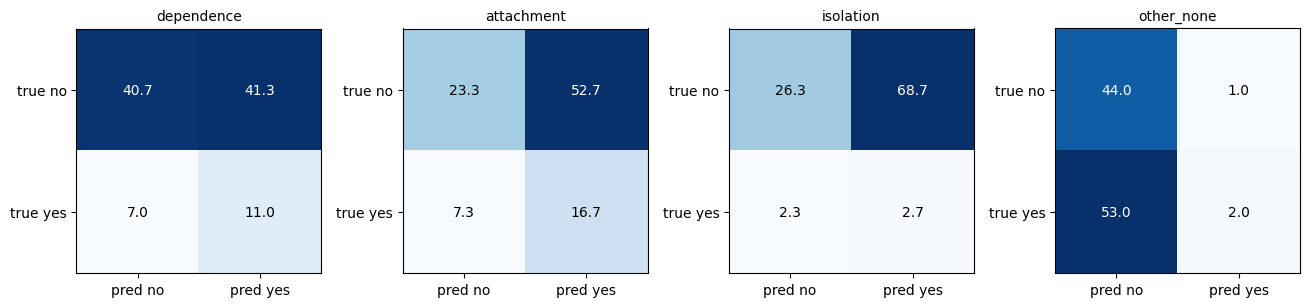

In [9]:
# Confusion matrices: counts averaged over the repeats.
def avg_confusion(c):
    return np.mean([confusion_matrix(y_all[c], p[c], labels=[0, 1]) for p in preds_by_repeat], axis=0)


cms = {c: avg_confusion(c) for c in CLASSES}
cm_df = pd.DataFrame({c: {'true positive': m[1, 1], 'false positive': m[0, 1],
                          'false negative': m[1, 0], 'true negative': m[0, 0]} for c, m in cms.items()}).T
print('Confusion counts per class (average over repeats):')
display(cm_df.round(1))
cm_df.round(2).to_csv(os.path.join(OUT_DIR, 'confusion_counts.csv'))

fig, axes = plt.subplots(1, len(CLASSES), figsize=(3.3 * len(CLASSES), 3.4), squeeze=False)
for ax, (name, m) in zip(axes[0], cms.items()):
    ax.imshow(m, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{m[i, j]:.1f}', ha='center', va='center', color='white' if m[i, j] > m.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['pred no', 'pred yes'])
    ax.set_yticks([0, 1], ['true no', 'true yes'])
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'confusion_matrices.png'), dpi=150)
plt.show()

## Interpretable features: which words push a review toward each theme?

In [10]:
final_models, thresholds = {}, {}
for t in TRAIN_THEMES:
    ch = choices[choices['label'] == t]
    C = ch['C'].mode().min()
    thresholds[t] = float(ch['threshold'].median())
    final_models[t] = make_pipe(TFIDF, C).fit(X, y_all[t])
    print(f'{t:11s} C = {C}   threshold = {thresholds[t]:.3f}')

top_words = {}
for t, model in final_models.items():
    vocab = model.named_steps['tfidf'].get_feature_names_out()
    coefs = model.named_steps['clf'].coef_[0]
    order = np.argsort(coefs)
    top_words[t] = pd.DataFrame({
        'toward theme': vocab[order[::-1][:15]], 'weight +': coefs[order[::-1][:15]].round(2),
        'away from theme': vocab[order[:15]], 'weight -': coefs[order[:15]].round(2),
    })
    print('\n' + t.upper() + f'   ({counts.loc[t, "status"]})')
    display(top_words[t])

dependence  C = 0.1   threshold = 0.482
attachment  C = 0.1   threshold = 0.480
isolation   C = 1.0   threshold = 0.225

DEPENDENCE   (trained)


,toward theme,weight +,away from theme,weight -
0,helps me,0.14,very,-0.07
1,my,0.14,the app,-0.06
2,me,0.12,are,-0.06
3,this app,0.11,so,-0.05
4,is the,0.10,free,-0.05
5,helps,0.10,amazing,-0.05
6,daily,0.08,an,-0.05
7,stress,0.08,much,-0.04
8,this,0.08,thank you,-0.04
9,with my,0.07,version,-0.04



ATTACHMENT   (trained)


,toward theme,weight +,away from theme,weight -
0,so,0.14,your,-0.07
1,best,0.10,the app,-0.07
2,my,0.10,very,-0.06
3,always,0.09,be,-0.06
4,who,0.09,the,-0.06
5,love,0.08,all,-0.05
6,with my,0.07,stress,-0.05
7,helped,0.07,app is,-0.05
8,so much,0.07,other,-0.05
9,especially,0.07,to,-0.05



ISOLATION   (trained, but scores unreliable)


,toward theme,weight +,away from theme,weight -
0,real,1.30,and,-0.52
1,therapy,1.11,helps,-0.38
2,all,1.04,was,-0.38
3,that it,0.82,my,-0.36
4,therapist,0.82,health,-0.33
5,you cant,0.81,on,-0.32
6,cant,0.81,better,-0.31
7,with,0.78,much,-0.29
8,already,0.73,free,-0.26
9,love,0.71,really,-0.26


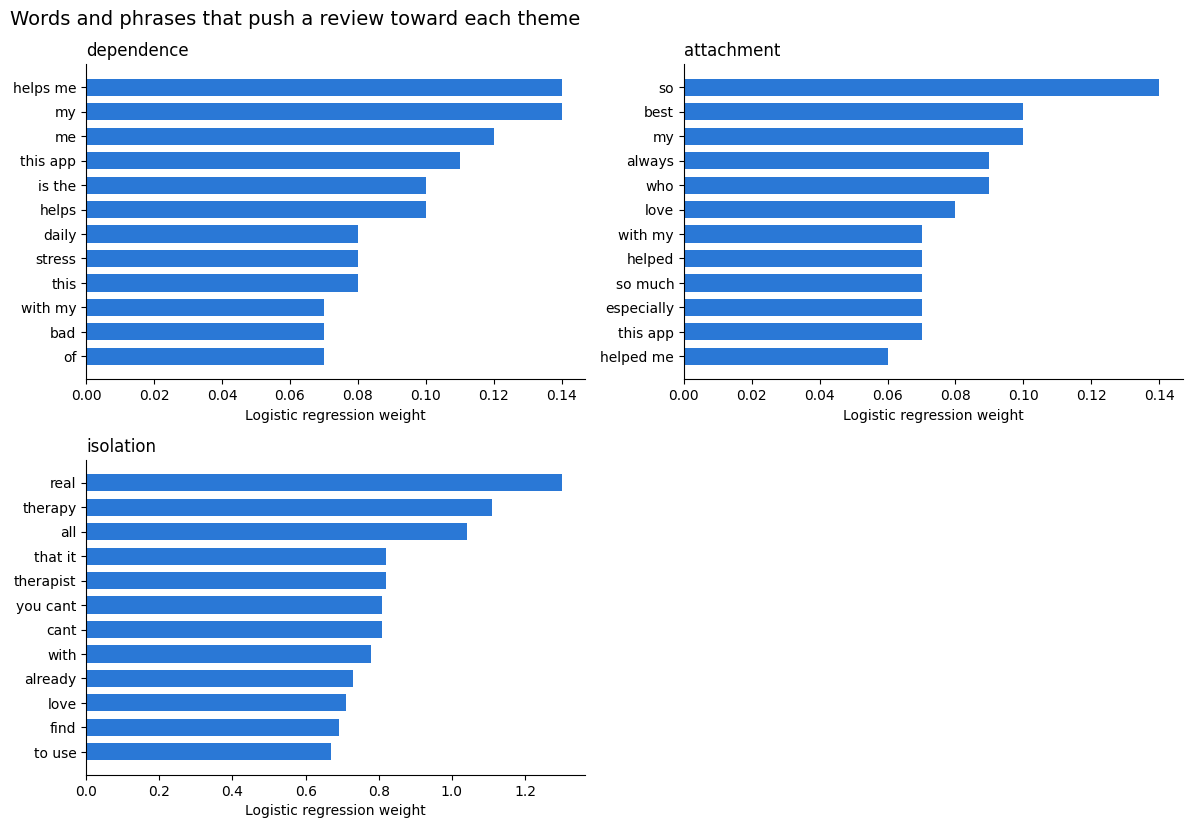

In [11]:
n_t = len(TRAIN_THEMES)
n_rows = int(np.ceil(n_t / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4.2 * n_rows), squeeze=False)
for ax in axes.ravel():
    ax.axis('off')
for ax, t in zip(axes.ravel(), TRAIN_THEMES):
    ax.axis('on')
    w = top_words[t].head(12).iloc[::-1]
    ax.barh(w['toward theme'], w['weight +'], color='#2a78d6', height=0.7)
    ax.set_title(t, loc='left', fontsize=12)
    ax.set_xlabel('Logistic regression weight')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
fig.suptitle('Words and phrases that push a review toward each theme', x=0.01, ha='left', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'top_words.png'), dpi=150)
plt.show()

## Save the rest

Cross-validated predictions for every review (from the first repeat), so you can read the reviews the model got wrong, plus the trained models.

In [12]:
oof = lab[['UID', 'review'] + [c for c in ['app_name', 'rating'] if c in lab.columns]].copy()
for c in CLASSES:
    oof[f'true_{c}'] = y_all[c]
    oof[f'pred_{c}'] = preds_by_repeat[0][c]
oof.to_csv(os.path.join(OUT_DIR, 'oof_predictions.csv'), index=False)
joblib.dump({'models': final_models, 'thresholds': thresholds, 'tfidf_setting': BEST},
            os.path.join(OUT_DIR, 'baseline_logreg_models.joblib'))
print('saved to', OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

# Example: reviews the model missed for the first modelled theme
t = TRAIN_THEMES[0]
missed = oof[(oof[f'true_{t}'] == 1) & (oof[f'pred_{t}'] == 0)]
print(f'\nExample: {len(missed)} reviews labelled "{t}" that the model missed')
display(missed[['review']].head(5))

saved to /content/drive/MyDrive/dataset/results
['baseline_logreg_models.joblib', 'confusion_counts.csv', 'confusion_matrices.png', 'oof_predictions.csv', 'results_table.csv', 'tfidf_settings_comparison.csv', 'top_words.png']

Example: 8 reviews labelled "dependence" that the model missed


,review
24,"I love it,its really useful for my personal health and my family indeed."
32,is like a friend who's always available for you in good or bad times and who doesn't give you advice but empower to...
37,I like this app a lot. It helps me fall asleep easily and gives me someone to vent to without fear of judgement. It ...
75,It is the best self care app you can tell them your problem like stress depression anxiety etc...... you have to dow...
81,"This is the only app that has ever worked for me, my mental health and happiness"
